In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [35]:
pd.set_option("display.max_columns",None)
sns.set_theme(rc = {'figure.figsize':(8,8)},font_scale = 1.3)

In [36]:
data = pd.read_csv(r"/content/WA_Fn-UseC_-HR-Employee-Attrition.csv",encoding = "latin_1")

In [37]:
data.head()

,ï»¿Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [38]:
data.tail()

,ï»¿Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,Y,No,17,3,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,Y,No,15,3,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Y,Yes,20,4,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,4,Male,63,2,2,Sales Executive,2,Married,5390,13243,2,Y,No,14,3,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,2,Male,82,4,2,Laboratory Technician,3,Married,4404,10228,2,Y,No,12,3,1,80,0,6,3,4,4,3,1,2


In [39]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   ï»¿Age                    1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [40]:
data.duplicated().sum()

np.int64(0)

In [41]:
data['Attrition_bool'] = data['Attrition'].map({'Yes': True,'No': False})
print(data ["Attrition_bool"].dtype)


bool


In [42]:
data.Attrition_bool.unique()

array([ True, False])

In [43]:
drop_cols = ['StandarHours','EmployeeNumber','EmployeeCount','Over18']
data = data.drop(columns=drop_cols,errors='ignore')
data.shape

(1470, 33)

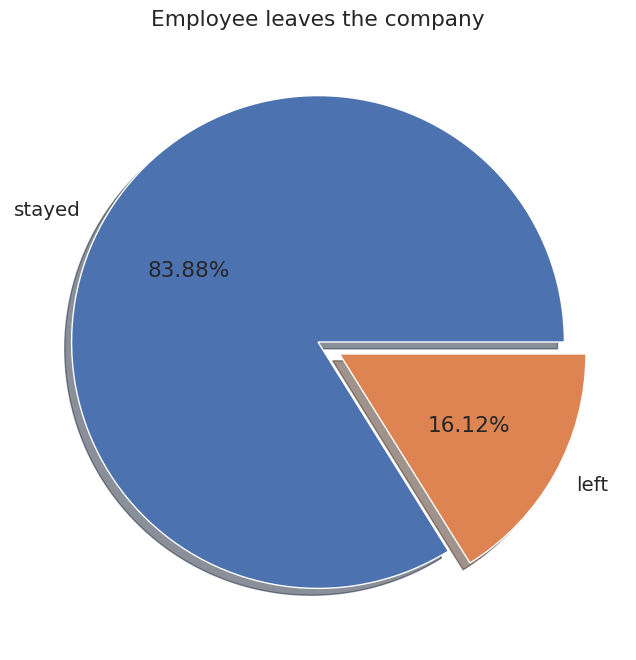

In [44]:

plt.pie(data['Attrition_bool'].value_counts(),labels =["stayed","left"],autopct="%.2f%%",shadow = "True",explode=(0,0.1))
plt.title("Employee leaves the company")
plt.show()

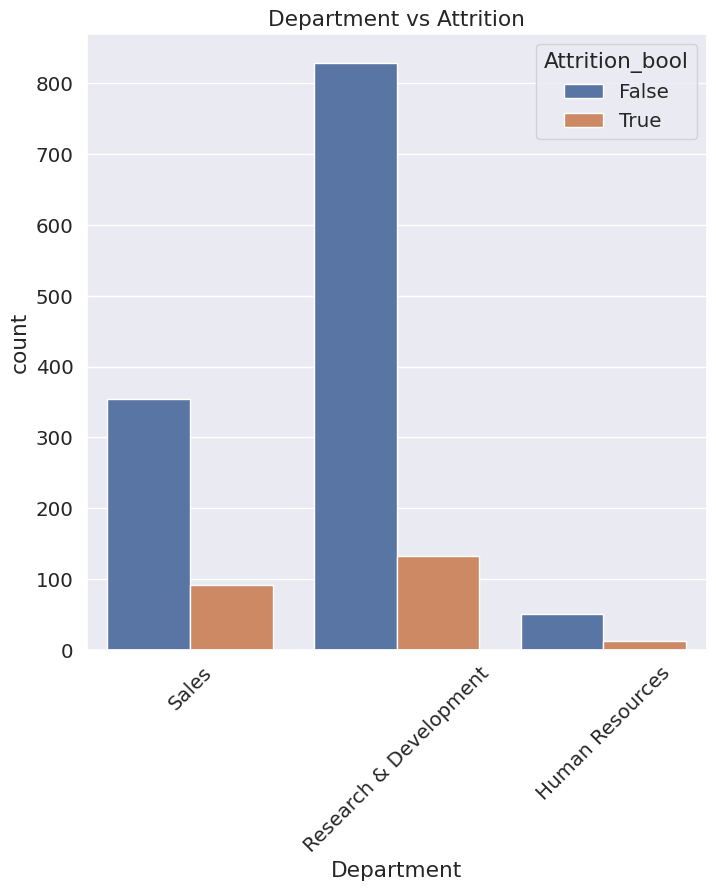

In [45]:
sns.countplot(data = data ,x="Department",hue="Attrition_bool")
plt.title("Department vs Attrition")
plt.xticks(rotation=45)
plt.show()


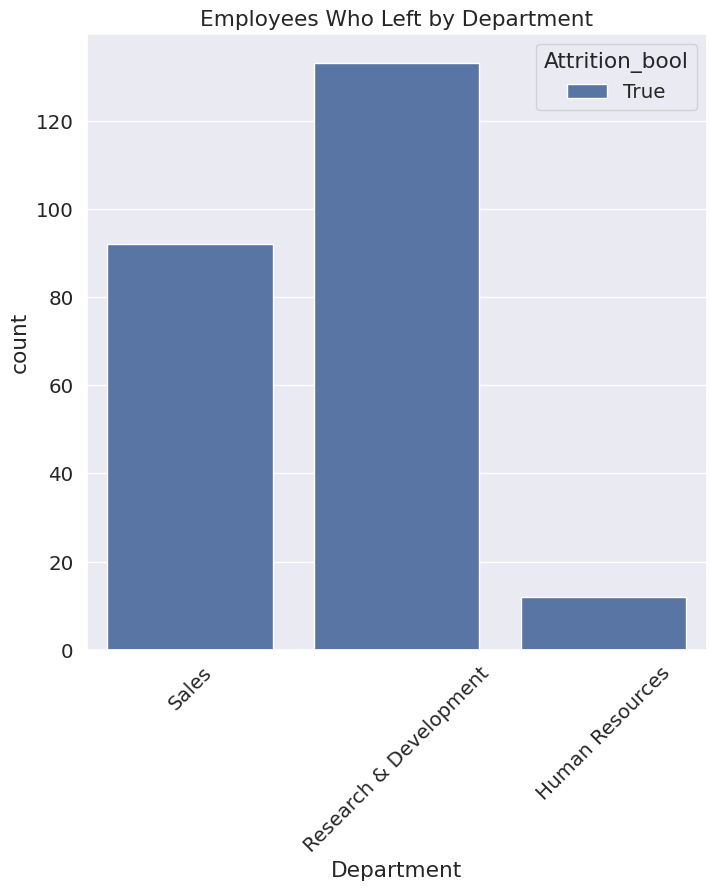

In [46]:
attrition_true=data[data['Attrition_bool']==True]
sns.countplot(data=attrition_true,x="Department",hue="Attrition_bool")
plt.title("Employees Who Left by Department")
plt.xticks(rotation=45)
plt.show()

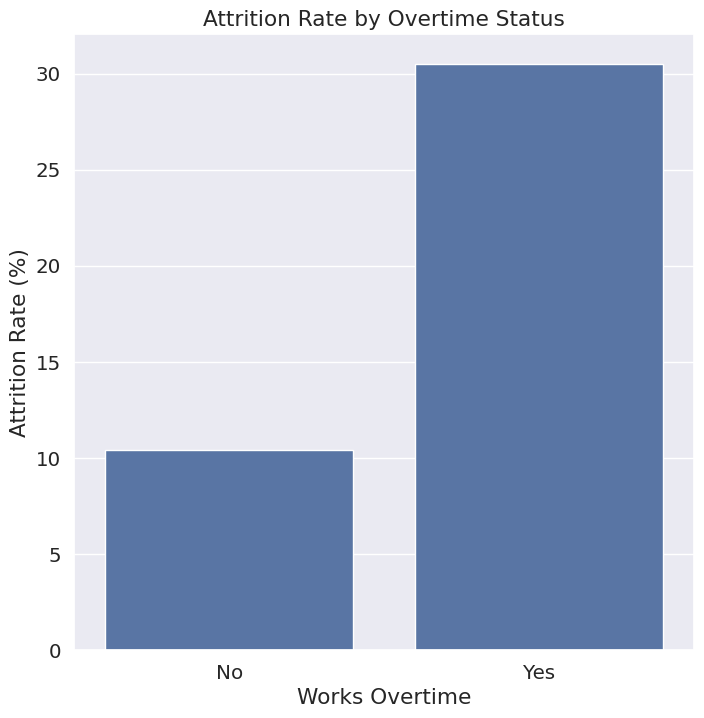

In [47]:
overtime_rate = data.groupby('OverTime')['Attrition_bool'].mean()*100
sns.barplot(x=overtime_rate.index,y=overtime_rate.values)
plt.title("Attrition Rate by Overtime Status")
plt.xlabel("Works Overtime")
plt.ylabel("Attrition Rate (%)")
plt.show()


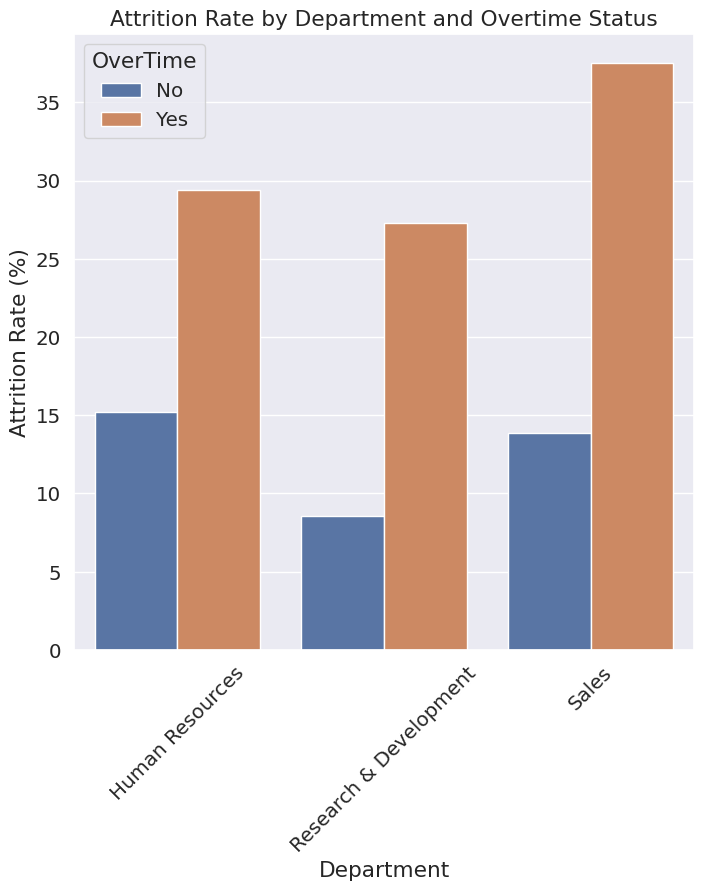

In [48]:
ovd_rate= data.groupby(["Department","OverTime"])["Attrition_bool"].mean().mul(100).reset_index()
sns.barplot(x="Department",y="Attrition_bool",hue="OverTime",data=ovd_rate)
plt.title("Attrition Rate by Department and Overtime Status")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45)
plt.show()


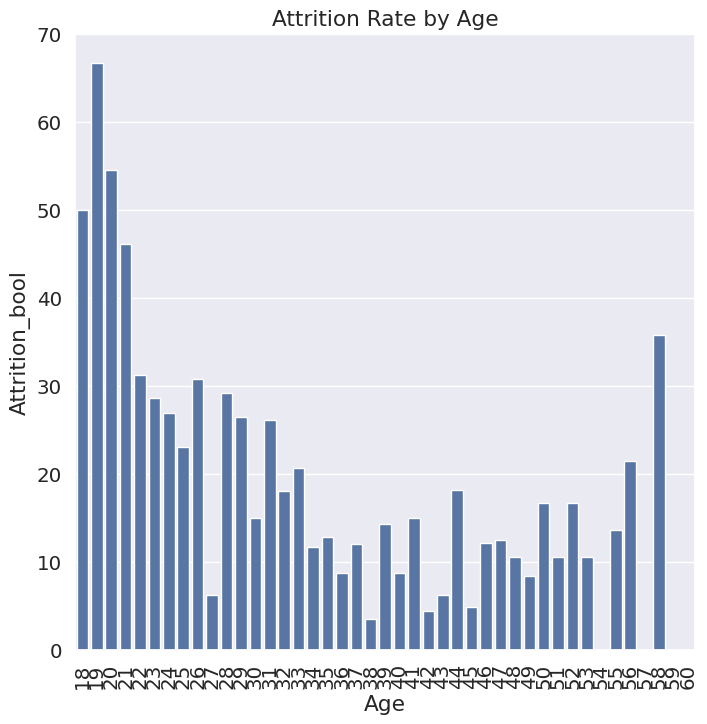

In [49]:
data.rename(columns={"ï»¿Age": "Age"}, inplace=True)
age_rate= data.groupby(["Age"])["Attrition_bool"].mean().mul(100).reset_index()
sns.barplot(data=age_rate,x="Age",y="Attrition_bool")
plt.title("Attrition Rate by Age")
plt.xlabel("Age")
plt.xticks(rotation=90)
plt.show()


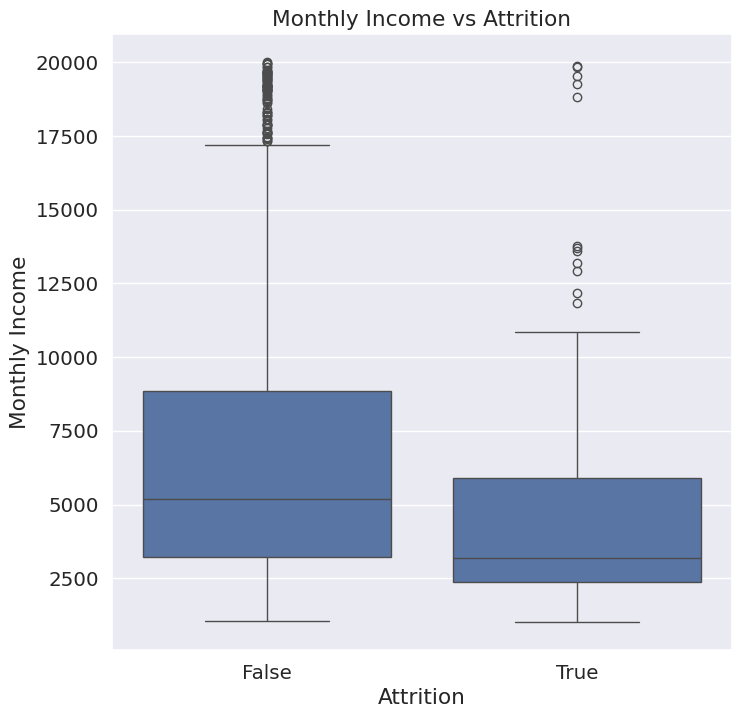

In [50]:
sns.boxplot(data=data,x="Attrition_bool" ,y="MonthlyIncome")
plt.title("Monthly Income vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.show()


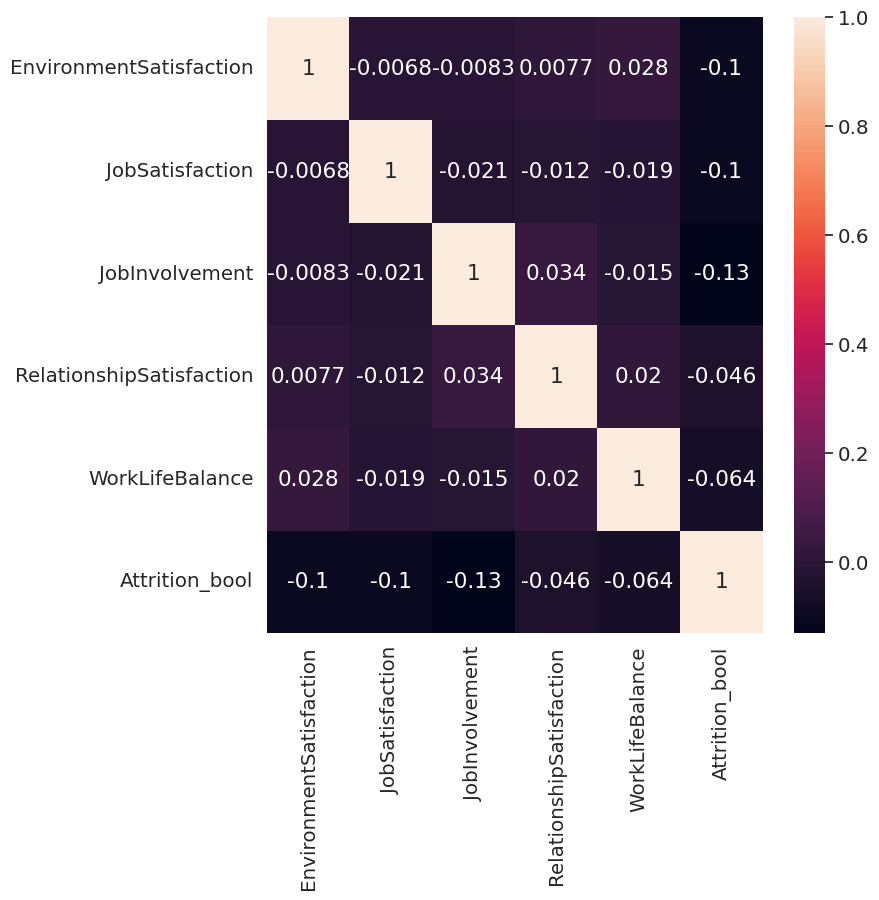

In [51]:
cols=["EnvironmentSatisfaction","JobSatisfaction","JobInvolvement","RelationshipSatisfaction","WorkLifeBalance","Attrition_bool"]
sns.heatmap(data[cols].corr(),annot=True)
plt.show()

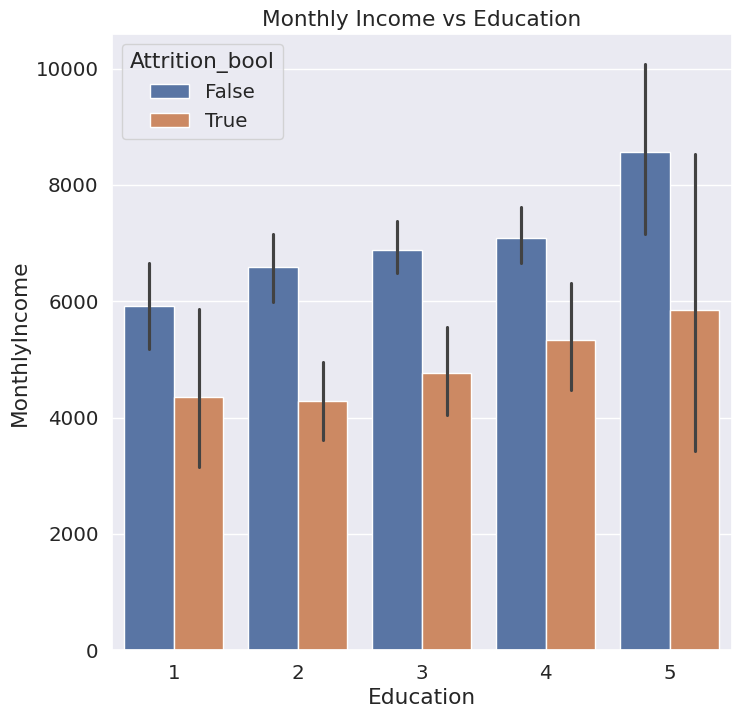

In [52]:
sns.barplot(data=data,x="Education",y="MonthlyIncome",hue="Attrition_bool")
plt.title("Monthly Income vs Education")
plt.xlabel("Education")
plt.show()

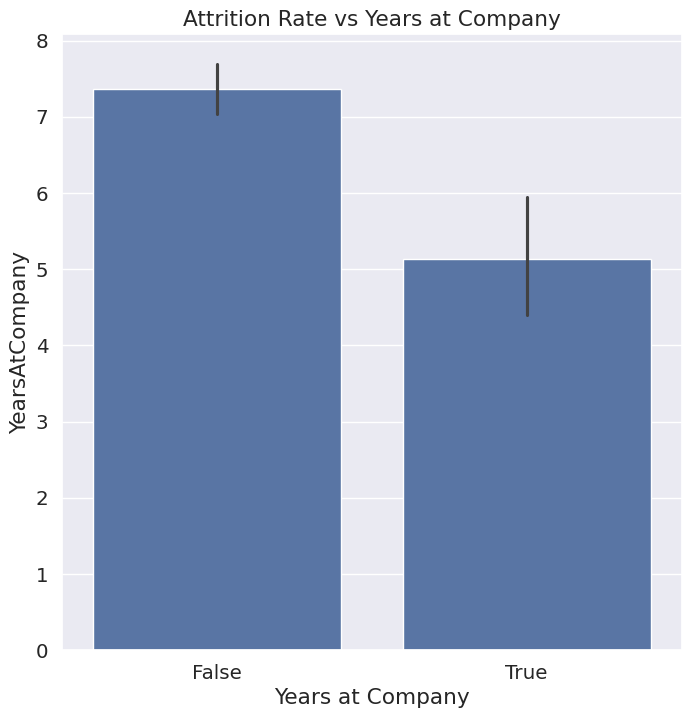

In [55]:
sns.barplot(data=data,y="YearsAtCompany",x="Attrition_bool")
plt.title("Attrition Rate vs Years at Company")
plt.xlabel("Years at Company")
plt.show()

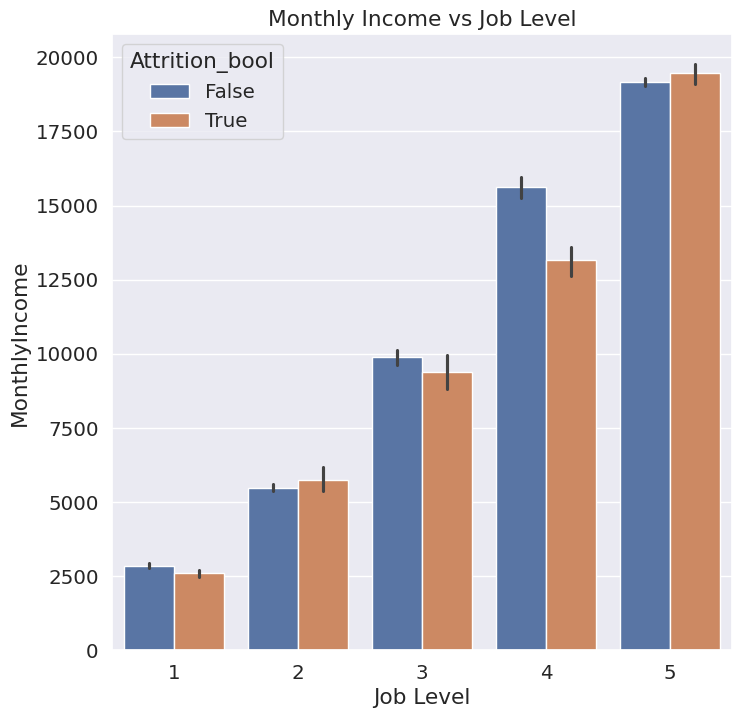

In [56]:
sns.barplot(data=data,x="JobLevel",y="MonthlyIncome",hue="Attrition_bool")
plt.title("Monthly Income vs Job Level")
plt.xlabel("Job Level")
plt.show()

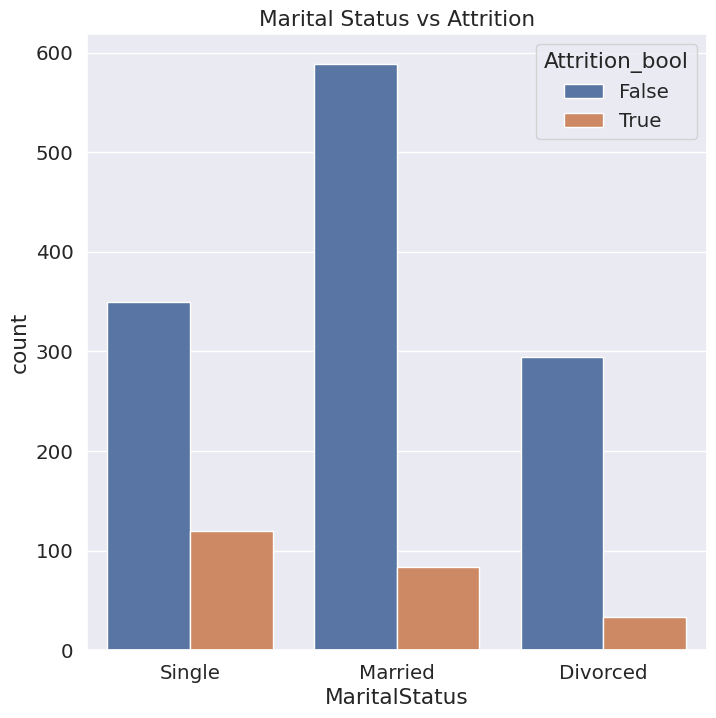

In [59]:
sns.countplot(data=data,x="MaritalStatus",hue="Attrition_bool")
plt.title("Marital Status vs Attrition")
plt.show()

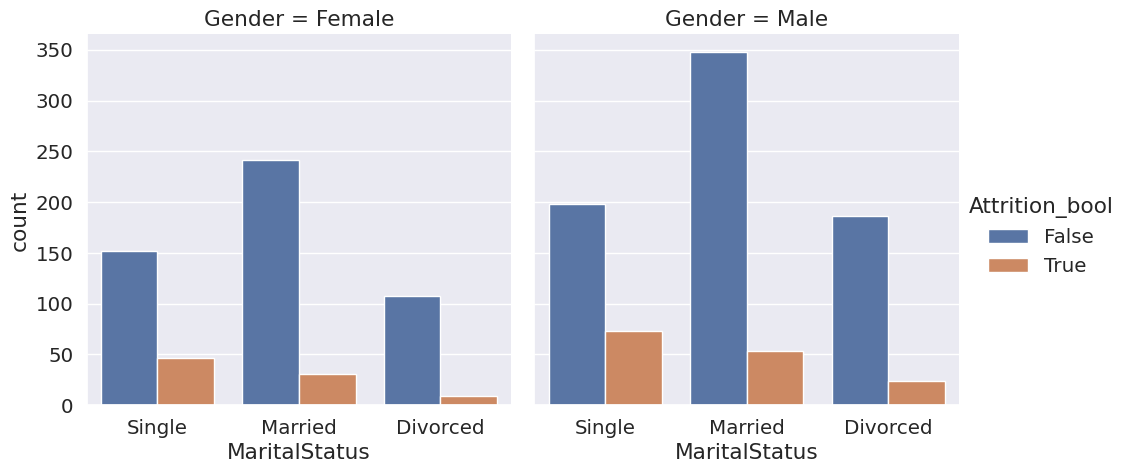

In [60]:
sns.catplot(data=data, x="MaritalStatus",hue="Attrition_bool",col="Gender",kind="count",height=5,aspect=1)
plt.show()